---
title: Sales Forecasting with Time-Varying Autoregressive Models (Part 4)
subtitle: Forecast real sales data
author: Kobus Esterhuysen
date: '2024-06-19'
date-modified: last-modified
categories:
  - Retail Industry
  - Bayesian Inference
  - Autoregressive (AR) Models
  - Active Inference
  - RxInfer
  - Julia
image: SalesForecastingWithTVAR-AR.jpeg
format:
  html:
    toc: true
    toc-depth: 4
    toc-expand: true
    toc-title: TOC
    code-fold: false
---

In [ ]:
#| hide
# BASED ON
  # SalesForecastingWithTVAR-AR4_PORT^v3.ipynb
  # SalesForecastingWithTVAR-AR4_PORT^v2.ipynb
  # SalesForecastingWithTVAR-AR4_PORT^v1.ipynb
  # SalesForecastingWithTVAR-AR3_PORT^v1.ipynb
  # SalesForecastingWithTVAR-AR2_PORT^v3.ipynb
  # SalesForecastingWithTVAR-AR2_PORT^v2.ipynb
  # SalesForecastingWithTVAR-AR2_PORT^v1.ipynb
  # Autoregressive Models_ANNO^v5.ipynb
  # Autoregressive Models_ANNO^v4.ipynb
  # Autoregressive Models_ANNO^v3.ipynb
  # Autoregressive Models_ANNO^v2.ipynb
  # Autoregressive Models.ipynb
# PUBLISH DEPENDENCIES
  # XXX_PORT.ipynb
# DONE
# v1 starts ------------------------------------------------
# migrated to RxInfer 3.0.0
# brought over my changes from RxInfer v2.16.2
# v2 starts ------------------------------------------------
# Change _n -> _N
# Change x -> s (state)
# Change order -> Mᴬᴿ
# Change θ, γ, τ -> θ̃, γ̃, τ̃
# Change states -> s̃s
# Change observations -> ys
# Change artype & T -> 𝚃ᴬᴿ
# standardize symbols to DeVries
# add math symbols to plots
# replace code vars with math symbols
  # makes mapping between literature and code better to enhance understanding
  # make expressions more concise due to reduced wordyness
# v3 starts ------------------------------------------------  
# Change generate_ar_data() to use matrices (small epsilon in V matrix so as not to break)
  # get error: AR-1 performs better than AR-5...
  # generated data appears somewhat different
  # parameters convert to different values (plot looks quite different)
  # I suspect sampling with the MvNormal is the culprit even though I tried with 1e-12*tiny
  # Will keep the matrix code for future, for now switch back to original code
# v4 starts ------------------------------------------------
# Change c -> v_u
# study posterior distributions
# plot θ_1,t tentatively to understand better
# Standardize plot colors
# Add alpha to ribbon plot to make it lighter
# v1 starts ------------------------------------------------
# Consolidate all initialization = ar_init(_Mᴬᴿ) into one function (i.e. also for M=1)
# Use multiple orders to find best model for synthetic data
# v2 starts ------------------------------------------------
# Publish
# v3 starts ------------------------------------------------
# Adjust transition & observation precisions
# Forecast into the future
# Two versions of generate_ar_data() function: with/without matrices
# Add offset to make sales positive
# Publish Part 3
# v1 starts ------------------------------------------------
# Use shampoo sales data
# Do experiments similar to 6.1 of paper
  # https://www2.stat.duke.edu/courses/Fall99/sta290/Notes/AR/ar.pdf
# v2 starts ------------------------------------------------
# Add AR diagram
# Update narrative
# Publish
# v3 starts ------------------------------------------------
# Upgrade to latest Julia (1.10.4)
# Upgrade to latest RxInfer (3.6.0)
# Publish
# v4 starts ------------------------------------------------
# migrate to cursor & github
# Bump Plots 1.40.1 -> 1.41.6 (Julia 1.12 precompile)
#  ̃ --> ˣ for environment vars (star)
# '...s' --> Char(0xA789) for sequences, i.e. not the usual :
# x --> y for observation
# s --> x for state
# | --> ; for parameterized by
# B --> A for system matrix
# _ for tensors, not globals
# γ --> λₓ for univariatestate precision
# τ --> λᵧ for univariate observation precision
# ensure best AR order is picked
# clean to publish

# TODO
# Insert 6 methods ?
# Insert (modified) CRISP-DM structure
# Replace hardcoded parameters with symbols


In Part 3 we did the first forecast beyond the available synthetic data. In this part, we make use of real sales data. As before, we use `RxInfer` to learn the best order (2) as well as the parameters $\boldsymbol\theta$ of the AR process. The inference process also learned the value of the transition precision parameter $\lambda_x$ as well as the $x_t$ state component which is the most recent sales amount.


In [2]:
versioninfo() ## Julia version

Julia Version 1.12.7
Commit 6d172b025e4 (2026-08-15 08:05 UTC)
Build Info:
  Official https://julialang.org release
Platform Info:
  OS: Linux (x86_64-linux-gnu)
  CPU: 12 × Intel(R) Core(TM) i7-8700B CPU @ 3.20GHz
  WORD_SIZE: 64
  LLVM: libLLVM-18.1.7 (ORCJIT, skylake)
  GC: Built with stock GC
Threads: 1 default, 1 interactive, 1 GC (on 12 virtual cores)


In [ ]:
import Pkg
Pkg.add(Pkg.PackageSpec(;name="RxInfer", version="3.6.0"))
Pkg.add(Pkg.PackageSpec(;name="Distributions", version="0.25.108"))
Pkg.add(Pkg.PackageSpec(;name="Random"))
Pkg.add(Pkg.PackageSpec(;name="Plots", version="1.41.6"))
Pkg.add(Pkg.PackageSpec(;name="LaTeXStrings", version="1.3.1"))
Pkg.add(Pkg.PackageSpec(;name="BenchmarkTools", version="1.5.0"))
Pkg.add(Pkg.PackageSpec(;name="Parameters", version="0.12.3"))
Pkg.add(Pkg.PackageSpec(;name="CSV", version="0.10.14"))
Pkg.add(Pkg.PackageSpec(;name="DataFrames", version="1.6.1"))

using RxInfer, Distributions, LinearAlgebra, Random, Plots, LaTeXStrings, BenchmarkTools, Parameters
using DataFrames, CSV

     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/envir

In [9]:
Pkg.status()

Status `~/.julia/environments/v1.12/Project.toml`
⌃ [6e4b80f9] BenchmarkTools v1.5.0
⌃ [336ed68f] CSV v0.10.14
⌃ [a93c6f00] DataFrames v1.6.1
⌃ [31c24e10] Distributions v0.25.108
⌃ [b964fa9f] LaTeXStrings v1.3.1
⌃ [d96e819e] Parameters v0.12.3
⌃ [91a5bcdd] Plots v1.41.6
⌃ [86711068] RxInfer v3.6.0
  [9a3f8284] Random v1.11.0
Info Packages marked with ⌃ have new versions available and may be upgradable.


In [4]:
## macro h(x) ## for help
#     quote
#         display("text/markdown", @doc $x)
#     end    
# end
# @h Normal() ## help on Normal()

Our model for the Variational Bayesian Inference of a latent autoregressive model can be represented mathematically as follows:

$$\begin{aligned}
p(\lambda_x) &= \mathcal{Gam}(\lambda_x;\ a, b)\\
p(\boldsymbol{\theta}) &= \mathcal{N}(\boldsymbol{\theta};\ \mathbf{m}_{\theta}, \mathbf{V}_{\theta})\\
p(\mathbf{x}_t \mid \mathbf{x}_{t-1}, \boldsymbol{\theta}) &= \mathcal{N}\left(\mathbf{x}_t;\ \mathbf{A}\left(\boldsymbol{\theta}\right) \mathbf{x}_{t-1},\, \mathbf{V}(\lambda_x)\right)\\
p(y_t \mid \mathbf{x}_t) &= \mathcal{N}(y_t;\ \mathbf{x}_t, \lambda_y^{-1})
\end{aligned}$$

where 

- $M^{AR}$ is the order of the autoregression process

- $\boldsymbol{\theta}=(\theta_1, \theta_2, ..., \theta_{M^{AR}})^{\top}$ is a vector of transition coefficients

- $\mathbf{x}_{t-1} = (x_{t-1}, x_{t-2}, ..., x_{t-M^{AR}})^\top$ is the previous state

- $\mathbf{x}_t = (x_{t}, x_{t-1}, ..., x_{t-M^{AR}+1})^\top$ is the current state

- $y_t$ is the current observation

- $\lambda_x$ is the state transition precision

- $\lambda_y$ is the observation generation precision

- $\mathbf{v}_u = (1,0,...,0)^\top$ is an $M^{AR}$-dimensional unit vector selecting the first component of the vector that follows

- $\mathbf{V}(\lambda_x) = (1/ \lambda_x)\mathbf{v}_u\mathbf{v}_u^\top$ is the transition covariance

- $\mathbf{A}(\boldsymbol{\theta}) = \begin{bmatrix} 
\boldsymbol{\qquad\theta}^\top \\ 
\mathbf{I}_{M^{AR}-1} & \mathbf{0} 
\end{bmatrix}$ is the transition matrix

The following diagram represents an autoregressive process:

![Autoregressive process](SalesForecastingWithTVAR-AR.png)

- change x to y
- change s to x

In [11]:
## Unicode character for ꞉ to indicate time sequences
## Copy and paste this printed form to the rest of the code identifier
## The previously used \lmrk (triangular) colon silently failed 
##  in GraphPPL.
print(Char(0xA789)) ## prints ꞉
repr(UInt32(last("_xˣ꞉"))) ## verify "0x0000a789"

꞉

"0x0000a789"

We downloaded the shampoo sales data from:

https://raw.githubusercontent.com/jbrownlee/Datasets/master/shampoo.csv

In [10]:
df = CSV.read("./shampoo.csv", DataFrame; delim=',')
df

Row,Month,Sales
,Date,Float64
1,0001-01-01,266.0
2,0001-02-01,145.9
3,0001-03-01,183.1
4,0001-04-01,119.3
5,0001-05-01,180.3
6,0001-06-01,168.5
7,0001-07-01,231.8
8,0001-08-01,224.5
9,0001-09-01,192.8


In [ ]:
y꞉ = df.Sales

36-element Vector{Float64}:
 266.0
 145.9
 183.1
 119.3
 180.3
 168.5
 231.8
 224.5
 192.8
 122.9
   ⋮
 439.3
 401.3
 437.4
 575.5
 407.6
 682.0
 475.3
 581.3
 646.9

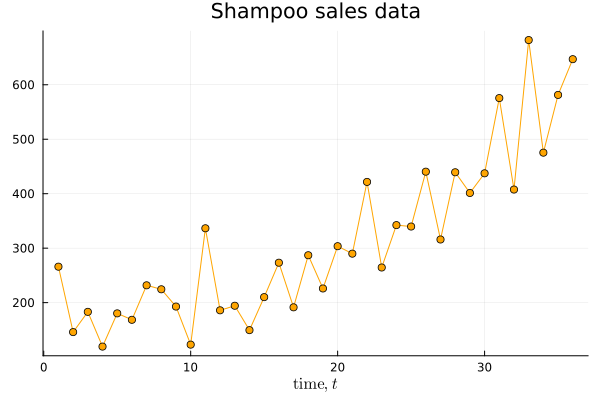

In [13]:
plot(
    y꞉, 
    title="Shampoo sales data",
    xlabel=L"$\mathrm{time}, t$",
    color="orange",
    legend=false
)
scatter!(y꞉, label=L"$\mathrm{Observation}, y_t$", color="orange")

In [ ]:
N = length(y꞉) ## Number of observations of the sales data
λˣᵧ = 0.001 ## assumed observation generation precision

0.001

Now we specify a probabilistic model, the inference constraints and then run an inference procedure with `RxInfer`. We need two different models for:

- Multivariate AR, with order $M^{AR} > 1$

- Univariate AR (reduces to a simple State-Space-Model), with order $M^{AR}$ = 1

In [15]:
@model function lar_model(
y꞉, ##. data/observations
𝚃ᴬᴿ, ##. Uni/Multi variate
Mᴬᴿ, ##. AR order
_vᵤ, ##. unit vector 
λᵧ) ##. generation precision     
    ## Priors
    λₓ  ~ Gamma(α = 1.0, β = 1.0) ##. for transition precision    
    if 𝚃ᴬᴿ === Multivariate
        _θ  ~ MvNormal(μ = zeros(Mᴬᴿ), Λ = diageye(Mᴬᴿ)) ##.kw μ,Λ only work inside macro
        _x₀ ~ MvNormal(μ = zeros(Mᴬᴿ), Λ = diageye(Mᴬᴿ)) ##.kw μ,Λ only work inside macro
    else ## Univariate
        _θ  ~ Normal(μ = 0.0, γ = 1.0)
        _x₀ ~ Normal(μ = 0.0, γ = 1.0)
    end
    _xₜ₋₁ = _x₀
    for t in eachindex(y꞉)
        _x꞉[t] ~ AR(_xₜ₋₁, _θ, λₓ) #.Eq (2b)
        if 𝚃ᴬᴿ === Multivariate
            y꞉[t] ~ Normal(μ = dot(_vᵤ, _x꞉[t]), γ = λᵧ) #.Eq (2c)
        else
            y꞉[t] ~ Normal(μ = _vᵤ*_x꞉[t], γ = λᵧ) #.Eq (2c)
        end
        _xₜ₋₁ = _x꞉[t]
    end
end

In [16]:
@constraints function ar_constraints() 
    q(_x₀, _x꞉, _θ, λₓ) = q(_x₀, _x꞉)q(_θ)q(λₓ)
end

ar_constraints (generic function with 1 method)

In [17]:
@meta function ar_meta(𝚃ᴬᴿ, Mᴬᴿ, stype)
    AR() -> ARMeta(𝚃ᴬᴿ, Mᴬᴿ, stype)
end

ar_meta (generic function with 1 method)

In [18]:
@initialization function ar_init(𝚃ᴬᴿ, Mᴬᴿ)
    q(λₓ) = GammaShapeRate(1.0, 1.0)
    if 𝚃ᴬᴿ === Multivariate    
        q(_θ) = MvNormalMeanPrecision(zeros(Mᴬᴿ), diageye(Mᴬᴿ))
    else ## Univariate
        q(_θ) = NormalMeanPrecision(0.0, 1.0)
    end
end

ar_init (generic function with 1 method)

In [19]:
function run_inference(Nmodels)
    results = Vector{Any}(undef, Nmodels)
    for m = 1:Nmodels
        println("m = $m")
        if m > 1 𝚃ᴬᴿ = Multivariate elseif m === 1 𝚃ᴬᴿ = Univariate
        else error("m=$m which is not an allowed value.") end    
        results[m] = infer(
            model = lar_model(
                𝚃ᴬᴿ=𝚃ᴬᴿ, ## Uni/Multi variate
                Mᴬᴿ=m, ## AR order
                _vᵤ=ReactiveMP.ar_unit(𝚃ᴬᴿ, m), ##. unit vector
                λᵧ=λˣᵧ), ## generation precision
            data = (y꞉=y꞉,),
            constraints   = ar_constraints(),
            meta          = ar_meta(𝚃ᴬᴿ, m, ARsafe()),
            options       = (limit_stack_depth = 100,),
            initialization = ar_init(𝚃ᴬᴿ, m),
            returnvars    = (_x꞉=KeepLast(), λₓ=KeepEach(), _θ=KeepEach()),
            free_energy   = true,
            iterations    = 100,
            showprogress  = false
        )
    end
    return(results)
end       

run_inference (generic function with 1 method)

Now we run the inference for $M^{AR}=1,2, ..., 7$:

In [20]:
results = run_inference(7)

m = 1
m = 2
m = 3
m = 4
m = 5
m = 6
m = 7


7-element Vector{Any}:
 Inference results:
  Posteriors       | available for (λₓ, _x꞉, _θ)
  Free Energy:     | Real[2307.28, 2306.57, 2306.14, 2305.47, 2304.17, 2300.56, 2281.64, 1974.21, 519.355, 294.064  …  233.459, 233.459, 233.459, 233.459, 233.459, 233.459, 233.459, 233.459, 233.459, 233.459]

 Inference results:
  Posteriors       | available for (λₓ, _x꞉, _θ)
  Free Energy:     | Real[2310.67, 2309.05, 2308.53, 2307.72, 2305.85, 2298.13, 2217.31, 1287.08, 319.798, 308.913  …  224.107, 224.107, 224.107, 224.107, 224.107, 224.107, 224.107, 224.107, 224.107, 224.107]

 Inference results:
  Posteriors       | available for (λₓ, _x꞉, _θ)
  Free Energy:     | Real[2314.14, 2311.41, 2310.77, 2309.86, 2307.58, 2296.03, 2149.49, 883.808, 338.662, 319.551  …  225.164, 225.164, 225.164, 225.164, 225.164, 225.164, 225.164, 225.164, 225.164, 225.164]

 Inference results:
  Posteriors       | available for (λₓ, _x꞉, _θ)
  Free Energy:     | Real[2317.59, 2313.75, 2312.93, 2311.94, 2309.39, 

In [21]:
function plot_free_energy(results)
    p = plot(title="Bethe Free Energy", legend=:topright, xlabel="iterations")
    for m = 1:length(results)
        p = plot!(p, results[m].free_energy, label="AR$m")
    end
    return p
end

plot_free_energy (generic function with 1 method)

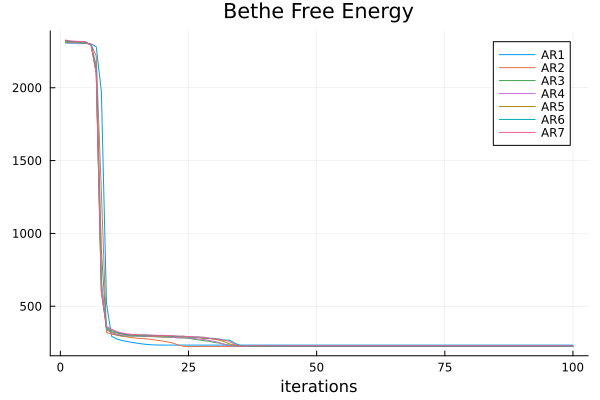

In [22]:
plot_free_energy(results)

In [23]:
values = [results[m].free_energy[end] for m in 1:length(results)]

7-element Vector{Float64}:
 233.4585521436341
 224.10729518548217
 225.16366364288
 226.21561906749105
 225.26562257539604
 225.88766886863914
 228.36387001925186

In [24]:
function plot_converged_free_energy(results)
    values = [results[m].free_energy[end] for m in 1:length(results)]
    bar(
        1:length(results), 
        values, 
        legend=:none, 
        ylim=(220, 235), 
        title="Converged Free Energy vs AR Order"
    )
    xlabel!("AR order")
    ylabel!("Minimum Free Energy")
end

plot_converged_free_energy (generic function with 1 method)

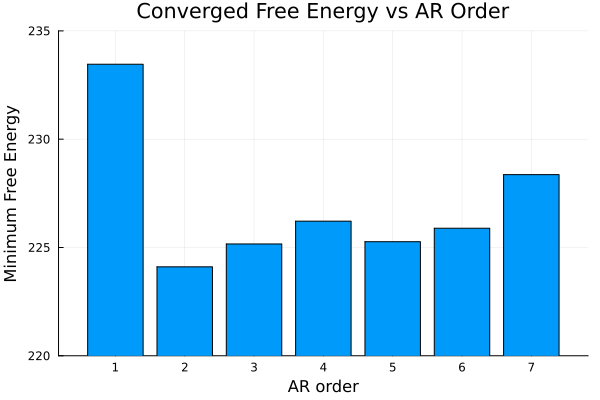

In [25]:
plot_converged_free_energy(results)

In [30]:
function plot_transition_precision(results)
    p = plot(
        title="Inferred transition precision", 
        legend=:topright, 
        xlabel="iterations"
    )
    for m = 1:length(results)
        p = plot!(p, mean.(results[m].posteriors[:λₓ]), label="AR$m")
    end
    ## plot!(
    ##     p, [λˣₓ], seriestype=:hline, color="red", linestyle=:dash, 
    ##     label=L"Real transition precision $\lambda_x^*$"
    ## )
    return p
end

plot_transition_precision (generic function with 1 method)

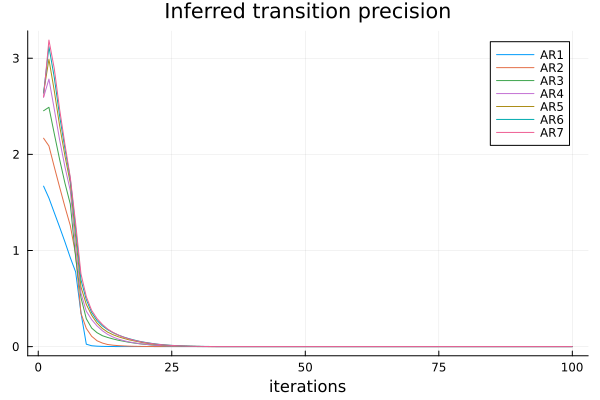

In [31]:
plot_transition_precision(results)

In [32]:
Mᵇᵉˢᵗ = 2 ## best order
@unpack _x꞉, _θ, λₓ = results[Mᵇᵉˢᵗ].posteriors

Dict{Symbol, Vector} with 3 entries:
  :λₓ  => GammaShapeRate{Float64}[GammaShapeRate{Float64}(a=19.0, b=8.76489), G…
  :_x꞉ => MvNormalWeightedMeanPrecision{Float64, Vector{Float64}, Matrix{Float6…
  :_θ  => MvNormalWeightedMeanPrecision{Float64, Vector{Float64}, Matrix{Float6…

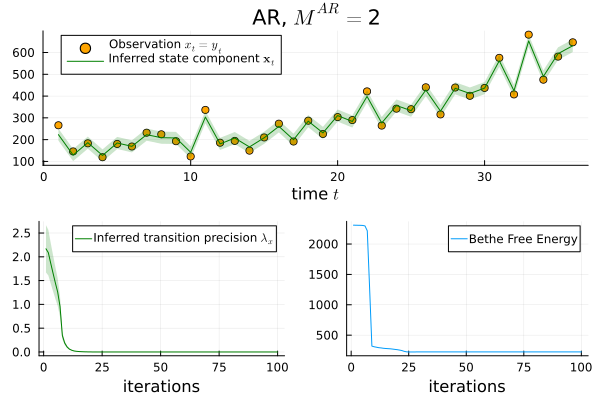

In [34]:
p1 = plot(
    ## first.(_xˣ꞉), ## first.() gives xˣₜ, not the delayed xˣₜ₋₁, xˣₜ₋₂, ..., xˣₜ₋ₘ₊₁
    title="AR, " * L"$M^{AR}=$" * "$Mᵇᵉˢᵗ",
    xlabel=L"time $t$",
    color="red",
    ## label=L"Hidden state component $\mathbf{x}^*_t$")
)
p1 = scatter!(p1, y꞉, label=L"Observation $x_t=y_t$", color="orange")
p1 = plot!(
    p1, first.(mean.(_x꞉)), 
    ribbon=first.(std.(_x꞉)), 
    fillalpha=0.2,
    label=L"Inferred state component $\mathbf{x}_t$",
    color="green",
    legend=:topleft)

p2 = plot(
    mean.(λₓ), ribbon=std.(λₓ), 
    fillalpha=0.2,
    label=L"Inferred transition precision $\lambda_x$", 
    color="green",
    legend=:topright,
    xlabel="iterations",
)
## p2 = plot!(
##     [λˣₓ], 
##     seriestype=:hline, 
##     color="red", #.
##     label=L"Real transition precision $\lambda_x^*$"
## )

p3 = plot(results[Mᵇᵉˢᵗ].free_energy, label="Bethe Free Energy", xlabel="iterations")
plot(p1, p2, p3, layout=@layout([ a; b c ]))

Let's look at a smaller range of data for the sake of interest:

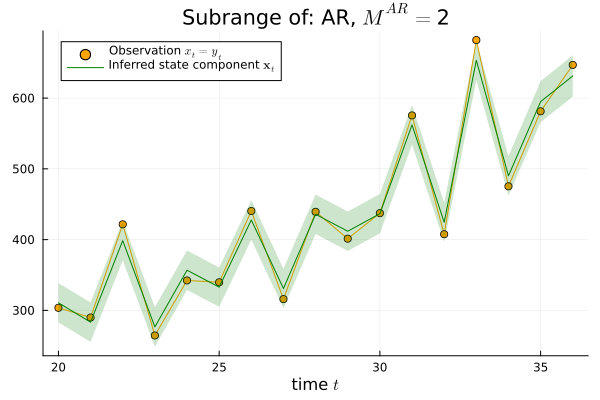

In [36]:
subrange = 20 : N
plot(
    subrange, 
    ## first.(_xˣ꞉)[subrange], 
    y꞉[subrange],
    title=L"Subrange of: AR, $M^{AR}=$"*"$Mᵇᵉˢᵗ",
    xlabel=L"time $t$",
    color="orange",
    label="",
)
scatter!(subrange, y꞉[subrange], label=L"Observation $x_t=y_t$", color="orange")
plot!(
    subrange, 
    first.(mean.(_x꞉))[subrange],
    ribbon=sqrt.(first.(var.(_x꞉)))[subrange],
    fillalpha=0.2,
    label=L"Inferred state component $\mathbf{x}_t$",
    color="green",
    legend=:topleft
)

Finally, we look at how the learned AR coefficients converge:

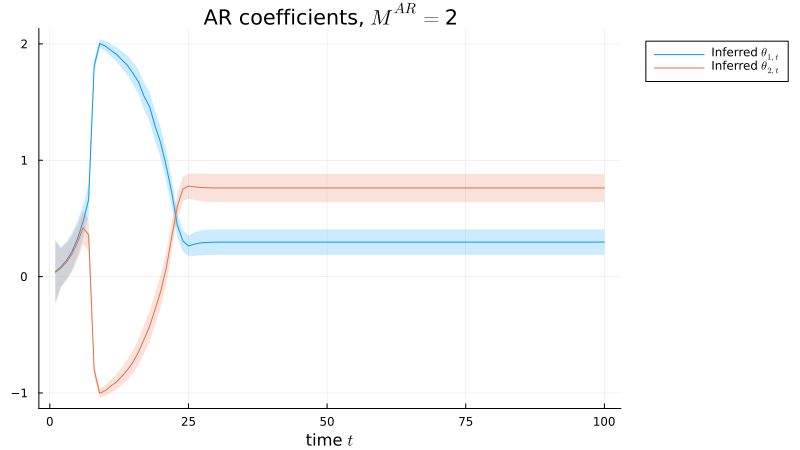

In [37]:
let
    pθ = plot()
    θms = mean.(_θ) ##. _θ means
    θvs = var.(_θ) ##. _θ variances
    l = length(θms)
    edim(e) = (a) -> map(r -> r[e], a)
    for t in 1:length(first(θms)) #.
        tmp = latexstring("\$ \\theta_{$(t),t} \$")
        pθ = plot!(
            pθ, 
            θms |> edim(t),
            ribbon=θvs |> edim(t) .|> sqrt, 
            fillalpha=0.2,
            label="Inferred $tmp")
    end
    ## for t in 1:length(_θ̃)
    ##     tmp = latexstring("\$ \\theta_{$(t),t} \$")
    ##     pθ = plot!(
    ##         pθ, 
    ##         [ _θˣ[t] ],
    ##         seriestype=:hline, 
    ##         label="Real $tmp")
    ## end
    plot(
        pθ, 
        title=L"AR coefficients, $M^{AR}=$"*"$Mᵇᵉˢᵗ",
        xlabel=L"time $t$",
        legend=:outertopright, 
        size=(800, 450))
end

Finally, we forecast a number of values into the future. First, we find the best value for $\theta$ and call it $\theta^{\mathrm{best}}$.

In [38]:
_θᵇᵉˢᵗ = mean(_θ[end])

2-element Vector{Float64}:
 0.29657911243285423
 0.761818040823179

In [39]:
_θᵇᵉˢᵗ[1], _θᵇᵉˢᵗ[2]

(0.29657911243285423, 0.761818040823179)

We decide to forecast 10 values into the future by having $n^{\mathrm{fcast}}=10$.

In [40]:
nᶠᶜᵃˢᵗ = 10 ## number of forecast values

10

In [42]:
x꞉ᶠᶜᵃˢᵗ = Vector{Float64}(undef, nᶠᶜᵃˢᵗ)

10-element Vector{Float64}:
 7.82e-321
 3.160017626e-315
 7.816e-321
 5.0e-324
 6.91145395881516e-310
 7.82e-321
 6.91145395881674e-310
 6.91152699161552e-310
 7.826e-321
 6.91146489174087e-310

In [43]:
## concat existing data with forecast to get complete signal
x꞉ᶜᵒᵐᵖˡ = [first.(mean.(_x꞉)); x꞉ᶠᶜᵃˢᵗ]

46-element Vector{Float64}:
 222.90905563878647
 129.10801335482827
 186.21297486503656
 127.3725139638895
 184.72878035452715
 169.1497400186742
 222.77794801609147
 208.92250166252242
 207.7460747904912
 141.80814711064664
   ⋮
   3.160017626e-315
   7.816e-321
   5.0e-324
   6.91145395881516e-310
   7.82e-321
   6.91145395881674e-310
   6.91152699161552e-310
   7.826e-321
   6.91146489174087e-310

Now we calculate the forecast values:

In [44]:
for t in N+1:N+nᶠᶜᵃˢᵗ
    x꞉ᶜᵒᵐᵖˡ[t] = _θᵇᵉˢᵗ[1]*x꞉ᶜᵒᵐᵖˡ[t-1] + _θᵇᵉˢᵗ[2]*x꞉ᶜᵒᵐᵖˡ[t-2]
end
x꞉ᶜᵒᵐᵖˡ

46-element Vector{Float64}:
 222.90905563878647
 129.10801335482827
 186.21297486503656
 127.3725139638895
 184.72878035452715
 169.1497400186742
 222.77794801609147
 208.92250166252242
 207.7460747904912
 141.80814711064664
   ⋮
 670.8915766914536
 686.895641153749
 714.8162061472319
 735.2890475654967
 762.6312548243156
 786.3369623244374
 814.1973667801112
 840.5196164496654
 869.5508046328605

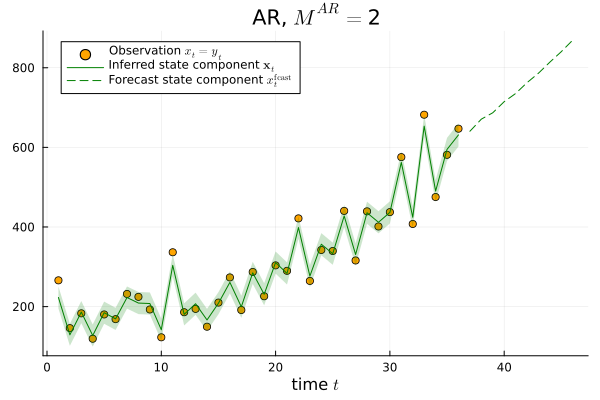

In [46]:
## subrange = 1:N
subrange = 1:N
pc1 = plot(
    ## subrange,
    ## first.(_xˣ꞉)[subrange], ## first.() gives xˣₜ, not the delayed xˣₜ₋₁, xˣₜ₋₂, ..., xˣₜ₋ₘ₊₁
    title="AR, " * L"$M^{AR}=$" * "$Mᵇᵉˢᵗ",
    xlabel=L"time $t$",
    ## color="red",
    ## label=L"Hidden state component $\mathbf{x}^*_t$",
    legend=:topleft)
pc1 = scatter!(pc1, 
    subrange,
    y꞉[subrange], label=L"Observation $x_t=y_t$", color="orange")
pc1 = plot!(pc1, 
    subrange,
    first.(mean.(_x꞉))[subrange], 
    ribbon=first.(std.(_x꞉))[subrange], 
    fillalpha=0.2,
    label=L"Inferred state component $\mathbf{x}_t$",
    color="green")
pc1 = plot!(pc1, 
    N+1:N+nᶠᶜᵃˢᵗ,
    x꞉ᶜᵒᵐᵖˡ[N+1:N+nᶠᶜᵃˢᵗ],
    title="AR, " * L"$M^{AR}=$" * "$Mᵇᵉˢᵗ",
    xlabel=L"time $t$",
    color="green",
    linestyle=:dash,
    label=L"Forecast state component $x^{\mathrm{fcast}}_t$")